In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

In [52]:
orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")
products = pd.read_csv("../data/raw/olist_products_dataset.csv")
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")
sellers = pd.read_csv("../data/raw/olist_sellers_dataset.csv")
reviews = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")
payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")

In [53]:
print("Orders:", orders.shape)
print("Order items:", order_items.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)
print("Sellers:", sellers.shape)
print("Reviews:", reviews.shape)
print("Payments:", payments.shape)

Orders: (99441, 8)
Order items: (112650, 7)
Products: (32951, 9)
Customers: (99441, 5)
Sellers: (3095, 4)
Reviews: (99224, 7)
Payments: (103886, 5)


In [54]:
orders.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [55]:
orders.info()


<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [56]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

orders[date_columns] = orders[date_columns].apply(pd.to_datetime)

In [57]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 6.1 MB


In [58]:
orders["delivery_time"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
)

In [59]:
orders["delivery_time"].head()



0    8 days 10:28:40
1   13 days 18:46:08
2    9 days 09:27:40
3   13 days 05:00:36
4    2 days 20:58:23
Name: delivery_time, dtype: timedelta64[us]

In [60]:
orders["delivery_time"].mean()

Timedelta('12 days 13:24:31.879068')

In [61]:
orders["late_delivery"] = (
    orders["order_delivered_customer_date"]
    > orders["order_estimated_delivery_date"]
)

In [62]:
orders["late_delivery"].value_counts()

late_delivery
False    91614
True      7827
Name: count, dtype: int64

In [63]:
orders["late_delivery"].mean() * 100


np.float64(7.870998883760219)

In [64]:
delivered_orders = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna()) &
    (orders["order_estimated_delivery_date"].notna())
]

In [65]:
orders["delivery_time"].describe()


count                      96476
mean     12 days 13:24:31.879068
std       9 days 13:07:00.181125
min              0 days 12:48:07
25%       6 days 18:23:37.250000
50%             10 days 05:13:34
75%      15 days 17:17:16.250000
max            209 days 15:05:12
Name: delivery_time, dtype: object

In [66]:
(orders["delivery_time"] > pd.Timedelta(days=30)).sum()


np.int64(4553)

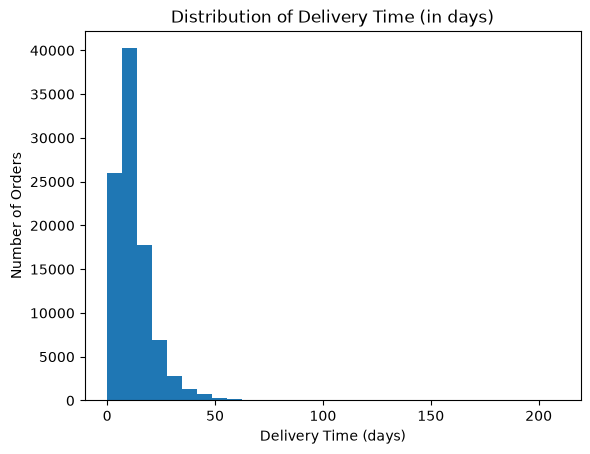

In [67]:
plt.Figure(figsize=(10, 5))
plt.hist(
    orders["delivery_time"].dt.days,
    bins=30,
)
plt.title("Distribution of Delivery Time (in days)")
plt.xlabel("Delivery Time (days)")
plt.ylabel("Number of Orders")

plt.show()

In [68]:
orders.sort_values("delivery_time", ascending=False)[
    ["order_id", "order_status", "delivery_time"]
].head(10)

,order_id,order_status,delivery_time
19590,ca07593549f1816d26a572e06dc1eab6,delivered,209 days 15:05:12
55619,1b3190b2dfa9d789e1f14c05b647a14a,delivered,208 days 08:26:32
61610,440d0d17af552815d15a9e41abe49359,delivered,195 days 15:12:59
70307,2fb597c2f772eca01b1f5c561bf6cc7b,delivered,194 days 20:24:15
89130,285ab9426d6982034523a855f55a885e,delivered,194 days 15:12:24
38509,0f4519c5f1c541ddec9f21b3bddd533a,delivered,194 days 01:11:24
11399,47b40429ed8cce3aee9199792275433f,delivered,191 days 11:07:30
81401,2fe324febf907e3ea3f2aa9650869fa5,delivered,189 days 20:42:57
54480,2d7561026d542c8dbd8f0daeadf67a43,delivered,188 days 03:13:51
68769,c27815f7e3dd0b926b58552628481575,delivered,187 days 17:51:08


In [69]:
orders.sort_values("delivery_time", ascending=False)[
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_time",
        "late_delivery"
    ]
].head(10)


,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_time,late_delivery
19590,ca07593549f1816d26a572e06dc1eab6,delivered,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,209 days 15:05:12,True
55619,1b3190b2dfa9d789e1f14c05b647a14a,delivered,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,208 days 08:26:32,True
61610,440d0d17af552815d15a9e41abe49359,delivered,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07,195 days 15:12:59,True
70307,2fb597c2f772eca01b1f5c561bf6cc7b,delivered,2017-03-08 18:09:02,2017-09-19 14:33:17,2017-04-17,194 days 20:24:15,True
89130,285ab9426d6982034523a855f55a885e,delivered,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,194 days 15:12:24,True
38509,0f4519c5f1c541ddec9f21b3bddd533a,delivered,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11,194 days 01:11:24,True
11399,47b40429ed8cce3aee9199792275433f,delivered,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,191 days 11:07:30,True
81401,2fe324febf907e3ea3f2aa9650869fa5,delivered,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,189 days 20:42:57,True
54480,2d7561026d542c8dbd8f0daeadf67a43,delivered,2017-03-15 11:24:27,2017-09-19 14:38:18,2017-04-13,188 days 03:13:51,True
68769,c27815f7e3dd0b926b58552628481575,delivered,2017-03-15 23:23:17,2017-09-19 17:14:25,2017-04-10,187 days 17:51:08,True


In [70]:
orders[
    orders["order_delivered_customer_date"].dt.date == pd.Timestamp("2017-09-19").date()
].shape

(282, 10)

In [71]:
orders[
    orders["order_delivered_customer_date"].dt.date == pd.Timestamp("2017-09-19").date()
]["delivery_time"].describe()

count                        282
mean     27 days 16:06:08.060283
std      44 days 05:39:18.601600
min              1 days 03:17:29
25%       7 days 20:36:19.250000
50%      11 days 19:15:51.500000
75%      21 days 14:02:12.250000
max            209 days 15:05:12
Name: delivery_time, dtype: object

In [72]:
product_customers = order_items.merge(
    orders[["order_id", "customer_id"]],
    on="order_id",
    how="left"
)

In [73]:
product_customers.groupby("product_id")["customer_id"].nunique().sort_values(ascending=False).head(10)

product_id
99a4788cb24856965c36a24e339b6058    467
aca2eb7d00ea1a7b8ebd4e68314663af    431
422879e10f46682990de24d770e7f83d    352
d1c427060a0f73f6b889a5c7c61f2ac4    323
389d119b48cf3043d311335e499d9c6b    311
53b36df67ebb7c41585e8d54d6772e08    306
368c6c730842d78016ad823897a372db    291
53759a2ecddad2bb87a079a1f1519f73    287
154e7e31ebfa092203795c972e5804a6    269
2b4609f8948be18874494203496bc318    259
Name: customer_id, dtype: int64

In [74]:
product_customers.groupby("product_id").size().sort_values(ascending=False).head(10)

product_id
aca2eb7d00ea1a7b8ebd4e68314663af    527
99a4788cb24856965c36a24e339b6058    488
422879e10f46682990de24d770e7f83d    484
389d119b48cf3043d311335e499d9c6b    392
368c6c730842d78016ad823897a372db    388
53759a2ecddad2bb87a079a1f1519f73    373
d1c427060a0f73f6b889a5c7c61f2ac4    343
53b36df67ebb7c41585e8d54d6772e08    323
154e7e31ebfa092203795c972e5804a6    281
3dd2a17168ec895c781a9191c1e95ad7    274
dtype: int64

In [75]:
product_price_customers = product_customers.groupby("product_id").agg(
    avg_price=("price", "mean"),
    unique_customers=("customer_id", "nunique")
).reset_index()

In [76]:
product_price_customers.head()

,product_id,avg_price,unique_customers
0,00066f42aeeb9f3007548bb9d3f33c38,101.65,1
1,00088930e925c41fd95ebfe695fd2655,129.90,1
2,0009406fd7479715e4bef61dd91f2462,229.00,1
3,000b8f95fcb9e0096488278317764d19,58.90,2
4,000d9be29b5207b54e86aa1b1ac54872,199.00,1


In [77]:
product_price_customers.corr(numeric_only=True)

,avg_price,unique_customers
avg_price,1.00,-0.03
unique_customers,-0.03,1.00


In [78]:
category_customers = product_customers.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

In [79]:
category_customers.groupby("product_category_name")["customer_id"].nunique().sort_values(ascending=False).head(10)

product_category_name
cama_mesa_banho           9417
beleza_saude              8836
esporte_lazer             7720
informatica_acessorios    6689
moveis_decoracao          6449
utilidades_domesticas     5884
relogios_presentes        5624
telefonia                 4199
automotivo                3897
brinquedos                3886
Name: customer_id, dtype: int64

In [80]:
order_value_freight = order_items.groupby("order_id").agg(
    order_value=("price", "sum"),
    freight_cost=("freight_value", "sum")
).reset_index()

In [81]:
order_value_freight.corr(numeric_only=True)

,order_value,freight_cost
order_value,1.00,0.41
freight_cost,0.41,1.00
